# Actividad Corte 2 — Modelo, consulta y limpieza de datos
**Dataset:** `stock_list.csv` — listado de valores de la Bolsa de Tokio (JPX), 4 417 filas × 16 columnas (corte al 30-dic-2021).
**Flujo:** 0) carga y diagnóstico → 1) limpieza → 2) reporte antes/después → 3) modelo relacional (ERD) en SQLite → 4) dos consultas con hallazgos.

In [1]:
import re, sqlite3, unicodedata
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)

RAW   = 'data/raw/stock_list.csv'
CLEAN = 'data/clean/stock_list_clean.csv'
raw = pd.read_csv(RAW)
raw.head()

,SecuritiesCode,EffectiveDate,Name,Section/Products,NewMarketSegment,33SectorCode,33SectorName,17SectorCode,17SectorName,NewIndexSeriesSizeCode,NewIndexSeriesSize,TradeDate,Close,IssuedShares,MarketCapitalization,Universe0
0,1301,20211230,"KYOKUYO CO.,LTD.",First Section (Domestic),Prime Market,50,"Fishery, Agriculture and Forestry",1,FOODS,7,TOPIX Small 2,20211230.0,3080.0,1.092828e+07,3.365911e+10,True
1,1305,20211230,Daiwa ETF-TOPIX,ETFs/ ETNs,NaN,-,-,-,-,-,-,20211230.0,2097.0,3.634636e+09,7.621831e+12,False
2,1306,20211230,NEXT FUNDS TOPIX Exchange Traded Fund,ETFs/ ETNs,NaN,-,-,-,-,-,-,20211230.0,2073.5,7.917718e+09,1.641739e+13,False
3,1308,20211230,Nikko Exchange Traded Index Fund TOPIX,ETFs/ ETNs,NaN,-,-,-,-,-,-,20211230.0,2053.0,3.736943e+09,7.671945e+12,False
4,1309,20211230,NEXT FUNDS ChinaAMC SSE50 Index Exchange Trade...,ETFs/ ETNs,NaN,-,-,-,-,-,-,20211230.0,44280.0,7.263200e+04,3.216145e+09,False


## 0. Diagnóstico inicial (ANTES)

In [2]:
def snapshot(d, placeholder='-'):
    obj = d.select_dtypes(exclude='number')
    return {
        'filas': len(d), 'columnas': d.shape[1],
        'nulos (NaN) totales': int(d.isna().sum().sum()),
        "placeholders '-' (nulos disfrazados)": int((d.astype(str) == placeholder).sum().sum()),
        'filas duplicadas (exactas)': int(d.duplicated().sum()),
        'códigos de valor duplicados': int(d.iloc[:, 0].duplicated().sum()) if d.columns[0] in ('SecuritiesCode','securities_code') else None,
    }
before = snapshot(raw)
before_extra = {
    'etiquetas distintas 17SectorName': raw['17SectorName'].nunique(),
    'etiquetas distintas Section/Products': raw['Section/Products'].nunique(),
    'columnas con tipo incorrecto (fechas como int/float, códigos numéricos)': 4,
}
print(before); print(before_extra)
print()
print('Nulos por columna:'); print(raw.isna().sum()[lambda s: s>0])
print()
print("Placeholders '-' por columna:"); print((raw=='-').sum()[lambda s: s>0])
print()
print('Tipos:'); print(raw.dtypes)

{'filas': 4417, 'columnas': 16, 'nulos (NaN) totales': 1829, "placeholders '-' (nulos disfrazados)": 6380, 'filas duplicadas (exactas)': 0, 'códigos de valor duplicados': 0}
{'etiquetas distintas 17SectorName': 34, 'etiquetas distintas Section/Products': 11, 'columnas con tipo incorrecto (fechas como int/float, códigos numéricos)': 4}

Nulos por columna:
NewMarketSegment        645
TradeDate               296
Close                   296
IssuedShares            296
MarketCapitalization    296
dtype: int64

Placeholders '-' por columna:
33SectorCode               500
33SectorName               500
17SectorCode               500
17SectorName               500
NewIndexSeriesSizeCode    2190
NewIndexSeriesSize        2190
dtype: int64

Tipos:
SecuritiesCode              int64
EffectiveDate               int64
Name                          str
Section/Products              str
NewMarketSegment              str
33SectorCode                  str
33SectorName                  str
17SectorCode  

Hallazgos del diagnóstico:

* **Nulos reales (NaN):** `NewMarketSegment` (645) y las 4 columnas de precio/cotización (296 filas sin dato de mercado).
* **Nulos disfrazados:** el texto `'-'` aparece en sectores (500) y en el índice de tamaño (2 190). No cuenta como nulo para pandas.
* **Formato inconsistente:** `17SectorName` tiene espacios finales (`'FOODS '` vs `'FOODS'`) → la misma categoría aparece como dos valores; además usa paréntesis de ancho completo `（EX BANKS）`.
* **Tipos incorrectos:** `EffectiveDate`/`TradeDate` son número (`20211230`, `20211230.0`) y no fecha; `IssuedShares` es float; los códigos son enteros aunque son identificadores.

In [3]:
print('Etiquetas 17SectorName (repr) con espacios finales:')
vc = raw['17SectorName'].map(repr).value_counts()
print(vc[vc.index.str.endswith(" '")].head(6))
print()
print("Mismo nombre, distintos códigos (nombres duplicados):")
raw[raw.Name.duplicated(keep=False)].sort_values('Name')[['SecuritiesCode','Name','Section/Products']]

Etiquetas 17SectorName (repr) con espacios finales:
17SectorName
'IT & SERVICES, OTHERS '                          1155
'RETAIL TRADE '                                    339
'COMMERCIAL & WHOLESALE TRADE '                    311
'CONSTRUCTION & MATERIALS '                        303
'ELECTRIC APPLIANCES & PRECISION INSTRUMENTS '     293
'RAW MATERIALS & CHEMICALS '                       288
Name: count, dtype: int64

Mismo nombre, distintos códigos (nombres duplicados):


,SecuritiesCode,Name,Section/Products
2386,6134,FUJI CORPORATION,First Section (Domestic)
3301,7605,FUJI CORPORATION,First Section (Domestic)
3679,8186,FUJI CORPORATION,JASDAQ(Standard / Domestic)
590,2479,JTEC CORPORATION,JASDAQ(Growth/Domestic)
1119,3446,JTEC CORPORATION,First Section (Domestic)
2426,6187,LITALICO Inc.,First Section (Domestic)
3167,7366,LITALICO Inc.,First Section (Domestic)
1120,3447,"Shinwa Co.,Ltd.",First Section (Domestic)
3303,7607,"Shinwa Co.,Ltd.",First Section (Domestic)
307,1885,TOA CORPORATION,First Section (Domestic)


## 1. Limpieza

### 1.1 Nombres de columnas y normalización de texto

In [4]:
df = raw.copy()
df = df.rename(columns={
    'SecuritiesCode':'securities_code','EffectiveDate':'effective_date','Name':'name',
    'Section/Products':'section_products','NewMarketSegment':'new_market_segment',
    '33SectorCode':'sector33_code','33SectorName':'sector33_name',
    '17SectorCode':'sector17_code','17SectorName':'sector17_name',
    'NewIndexSeriesSizeCode':'index_size_code','NewIndexSeriesSize':'index_size',
    'TradeDate':'trade_date','Close':'close','IssuedShares':'issued_shares',
    'MarketCapitalization':'market_cap','Universe0':'in_universe'})

def norm_text(s):
    if pd.isna(s): return s
    s = unicodedata.normalize('NFKC', str(s))      # （ ） -> ( )
    return re.sub(r'\s+', ' ', s).strip()           # espacios repetidos / finales

text_cols = ['name','section_products','new_market_segment','sector33_code','sector33_name',
             'sector17_code','sector17_name','index_size_code','index_size']
for c in text_cols:
    df[c] = df[c].map(norm_text)

# Estilo uniforme en section_products: 'ETFs/ ETNs' -> 'ETFs/ETNs', 'JASDAQ(Standard / Domestic)' -> 'JASDAQ (Standard/Domestic)'
df['section_products'] = (df['section_products']
    .str.replace(r'\s*/\s*', '/', regex=True)
    .str.replace(r'(?<=\w)\(', ' (', regex=True))

print('sector17_name distintos:', raw['17SectorName'].nunique(), '->', df['sector17_name'].nunique())
print('section_products distintos:', raw['Section/Products'].nunique(), '->', df['section_products'].nunique())
df['section_products'].value_counts()

sector17_name distintos: 34 -> 18
section_products distintos: 11 -> 11


section_products
First Section (Domestic)                                       2327
JASDAQ (Standard/Domestic)                                      726
Second Section (Domestic)                                       530
Mothers (Domestic)                                              439
ETFs/ETNs                                                       277
REIT, Venture Funds, Country Funds and Infrastructure Funds      68
JASDAQ (Growth/Domestic)                                         41
First Section (Foreign)                                           4
Mothers (Foreign)                                                 3
JASDAQ (Standard/Foreign)                                         1
Second Section (Foreign)                                          1
Name: count, dtype: int64

### 1.2 Tipos de dato y tipo de instrumento

In [5]:
df['effective_date'] = pd.to_datetime(df['effective_date'].astype(str), format='%Y%m%d')
df['trade_date']     = pd.to_datetime(df['trade_date'].astype('Int64').astype('string'), format='%Y%m%d', errors='coerce')
df['issued_shares']  = df['issued_shares'].round().astype('Int64')
df['market_cap']     = df['market_cap'].round().astype('Int64')
df['securities_code']= df['securities_code'].astype(str)          # identificador, no número
df['in_universe']    = df['in_universe'].astype(bool)

# Columna derivada: tipo de instrumento (los fondos no tienen sector ni segmento)
def instrument(s):
    if s.startswith('ETFs'): return 'ETF/ETN'
    if s.startswith('REIT'): return 'REIT/Fund'
    return 'Equity'
df['instrument_type'] = df['section_products'].map(instrument)
df['instrument_type'].value_counts()

instrument_type
Equity       4072
ETF/ETN       277
REIT/Fund      68
Name: count, dtype: int64

### 1.3 Nulos: `'-'` → NaN, imputación y eliminación

Reglas (cada una con su justificación):

| Columna | Situación | Decisión |
|---|---|---|
| sectores 33/17 (`'-'`) | ETF/REIT no tienen sector industrial | imputar `Not applicable (fund)` (código `NA`) |
| sectores 33/17 (`'-'`) | acciones sin clasificación | imputar `Unclassified` (código `UNC`) |
| `new_market_segment` (NaN) | igual criterio: fondos vs acciones sin segmento nuevo | `Not applicable (fund)` / `Unassigned` |
| `index_size` (`'-'`) | no pertenece a un índice TOPIX por tamaño (información válida) | imputar `Not in TOPIX size index`, código `NA` |
| `trade_date`, `close`, `issued_shares`, `market_cap` (NaN) | 296 acciones **sin cotización** en la fecha; inventar un precio sería falso | **eliminar** del dataset de análisis (se guardan aparte) |

In [6]:
df = df.replace('-', np.nan)          # nulos disfrazados -> NaN reales
print('NaN tras reemplazar "-":'); print(df.isna().sum()[lambda s: s>0])

is_fund = df['instrument_type'] != 'Equity'
for col_code, col_name in [('sector33_code','sector33_name'), ('sector17_code','sector17_name')]:
    df.loc[df[col_name].isna() &  is_fund, [col_code, col_name]] = ['NA',  'Not applicable (fund)']
    df.loc[df[col_name].isna() & ~is_fund, [col_code, col_name]] = ['UNC', 'Unclassified']

df.loc[df['new_market_segment'].isna() &  is_fund, 'new_market_segment'] = 'Not applicable (fund)'
df.loc[df['new_market_segment'].isna() & ~is_fund, 'new_market_segment'] = 'Unassigned'
df['index_size_code'] = df['index_size_code'].fillna('NA')
df['index_size']      = df['index_size'].fillna('Not in TOPIX size index')

# eliminación: valores sin cotización
no_price = df['close'].isna()
dropped = df[no_price].copy()
dropped.to_csv('data/clean/stock_list_dropped_no_price.csv', index=False)
df = df[~no_price].copy()
print(f'Filas eliminadas por no tener cotización: {len(dropped)} (guardadas en data/clean/stock_list_dropped_no_price.csv)')
print('Nulos restantes:', int(df.isna().sum().sum()))

NaN tras reemplazar "-":
new_market_segment     645
sector33_code          500
sector33_name          500
sector17_code          500
sector17_name          500
index_size_code       2190
index_size            2190
trade_date             296
close                  296
issued_shares          296
market_cap             296
dtype: int64
Filas eliminadas por no tener cotización: 296 (guardadas en data/clean/stock_list_dropped_no_price.csv)
Nulos restantes: 0


### 1.4 Duplicados

In [7]:
n0 = len(df)
df = df.drop_duplicates()                              # duplicados exactos
df = df.drop_duplicates(subset='securities_code')     # llave natural
print('Duplicados exactos / por código eliminados:', n0 - len(df))
dup_names = df[df.name.duplicated(keep=False)].sort_values('name')[['securities_code','name','section_products','close']]
print('\nNombres repetidos pero con códigos distintos (son valores distintos -> se conservan):')
dup_names

Duplicados exactos / por código eliminados: 0

Nombres repetidos pero con códigos distintos (son valores distintos -> se conservan):


,securities_code,name,section_products,close
2386,6134,FUJI CORPORATION,First Section (Domestic),2582.0
3301,7605,FUJI CORPORATION,First Section (Domestic),1176.0
590,2479,JTEC CORPORATION,JASDAQ (Growth/Domestic),200.0
1119,3446,JTEC CORPORATION,First Section (Domestic),1825.0
1120,3447,"Shinwa Co.,Ltd.",First Section (Domestic),845.0
3303,7607,"Shinwa Co.,Ltd.",First Section (Domestic),2159.0
307,1885,TOA CORPORATION,First Section (Domestic),2420.0
2833,6809,TOA CORPORATION,First Section (Domestic),808.0


### 1.5 Validaciones de consistencia

In [8]:
# Capitalización ≈ cierre × acciones emitidas
diff = (df['close'] * df['issued_shares'].astype('float') - df['market_cap'].astype('float')).abs()
rel = diff / df['market_cap'].astype('float')
assert rel.max() < 1e-6, rel.max()   # tolerancia por redondeo a entero (1 fila trae IssuedShares fraccionario)
assert (df['close'] > 0).all() and (df['issued_shares'] > 0).all()
assert df['securities_code'].is_unique
assert df['trade_date'].between('2021-01-01', '2021-12-31').all()
# Jerarquía: cada sector de 33 pertenece a un solo sector de 17 -> permite normalizar el modelo
assert df.groupby('sector33_code')['sector17_code'].nunique().max() == 1
print('Validaciones OK  |  diferencia relativa máx. close×shares vs market_cap = %.2e' % rel.max())

for c in ['section_products','new_market_segment','sector33_name','sector17_name','index_size','instrument_type']:
    df[c] = df[c].astype('category')
df = df.sort_values('securities_code', key=lambda s: s.astype(int)).reset_index(drop=True)
df.to_csv(CLEAN, index=False)
df.dtypes

Validaciones OK  |  diferencia relativa máx. close×shares vs market_cap = 3.46e-09


securities_code                  str
effective_date        datetime64[us]
name                             str
section_products            category
new_market_segment          category
sector33_code                    str
sector33_name               category
sector17_code                    str
sector17_name               category
index_size_code                  str
index_size                  category
trade_date            datetime64[us]
close                        float64
issued_shares                  Int64
market_cap                     Int64
in_universe                     bool
instrument_type             category
dtype: object

## 2. Reporte ANTES / DESPUÉS

In [9]:
after = snapshot(df.assign(**{c: df[c].astype(str) for c in df.select_dtypes('category')}))
after_extra = {
    'etiquetas distintas 17SectorName': df['sector17_name'].nunique(),
    'etiquetas distintas Section/Products': df['section_products'].nunique(),
}
rows = {
 'Filas': (before['filas'], after['filas']),
 'Columnas': (before['columnas'], after['columnas']),
 'Nulos (NaN) totales': (before['nulos (NaN) totales'], after['nulos (NaN) totales']),
 "Placeholders '-'": (before["placeholders '-' (nulos disfrazados)"], after["placeholders '-' (nulos disfrazados)"]),
 'Filas duplicadas exactas': (before['filas duplicadas (exactas)'], after['filas duplicadas (exactas)']),
 'Códigos duplicados': (before['códigos de valor duplicados'], int(df.securities_code.duplicated().sum())),
 'Etiquetas distintas sector17': (raw['17SectorName'].nunique(), df['sector17_name'].nunique()),
 'Etiquetas distintas section/products': (raw['Section/Products'].nunique(), df['section_products'].nunique()),
 'Columnas de fecha con tipo datetime': (0, int(df.select_dtypes('datetime').shape[1])),
 'Memoria (KB)': (round(raw.memory_usage(deep=True).sum()/1024), round(df.memory_usage(deep=True).sum()/1024)),
}
report = pd.DataFrame(rows, index=['Antes','Después']).T
report

,Antes,Después
Filas,4417,4121
Columnas,16,17
Nulos (NaN) totales,1829,0
Placeholders '-',6380,0
Filas duplicadas exactas,0,0
Códigos duplicados,0,0
Etiquetas distintas sector17,34,18
Etiquetas distintas section/products,11,11
Columnas de fecha con tipo datetime,0,2
Memoria (KB),2561,1324


In [10]:
cmp = pd.DataFrame({'nulos antes (NaN)': raw.isna().sum().values,
                    "'-' antes": (raw=='-').sum().values}, index=raw.columns)
cmp['nulos después'] = [0]*len(cmp)
cmp

,nulos antes (NaN),'-' antes,nulos después
SecuritiesCode,0,0,0
EffectiveDate,0,0,0
Name,0,0,0
Section/Products,0,0,0
NewMarketSegment,645,0,0
33SectorCode,0,500,0
33SectorName,0,500,0
17SectorCode,0,500,0
17SectorName,0,500,0
NewIndexSeriesSizeCode,0,2190,0


In [11]:
report.to_csv('data/clean/before_after_report.csv')
print(df.dtypes.to_string())

securities_code                  str
effective_date        datetime64[us]
name                             str
section_products            category
new_market_segment          category
sector33_code                    str
sector33_name               category
sector17_code                    str
sector17_name               category
index_size_code                  str
index_size                  category
trade_date            datetime64[us]
close                        float64
issued_shares                  Int64
market_cap                     Int64
in_universe                     bool
instrument_type             category


## 3. Modelo relacional (ERD) y carga en SQLite
El ERD completo (Mermaid, con cardinalidades) está en `docs/erd.md` y en el README. Aquí se materializa en SQLite para consultar con SQL.

In [12]:
con = sqlite3.connect('data/clean/stock_market.db')
con.executescript(open('sql/schema.sql').read())

def load(table, frame): frame.to_sql(table, con, if_exists='append', index=False)

load('market_segment', df[['new_market_segment']].drop_duplicates().rename(columns={'new_market_segment':'segment_name'}).astype(str).sort_values('segment_name'))
load('sector17', df[['sector17_code','sector17_name']].drop_duplicates().astype(str).sort_values('sector17_code'))
load('sector33', df[['sector33_code','sector33_name','sector17_code']].drop_duplicates().astype(str).sort_values('sector33_code'))
load('index_size', df[['index_size_code','index_size']].drop_duplicates().astype(str).rename(columns={'index_size':'index_size_name'}))

seg = pd.read_sql('select * from market_segment', con).set_index('segment_name')['segment_id']
sec = df.assign(segment_id=df['new_market_segment'].astype(str).map(seg),
                effective_date=df['effective_date'].dt.strftime('%Y-%m-%d'))
load('security', sec[['securities_code','name','instrument_type','section_products','in_universe','effective_date',
                      'segment_id','sector33_code','index_size_code']].astype({'instrument_type':str,'section_products':str}))
load('price_snapshot', df.assign(trade_date=df['trade_date'].dt.strftime('%Y-%m-%d'))[
    ['securities_code','trade_date','close','issued_shares','market_cap']].astype({'issued_shares':'int64','market_cap':'int64'}))

for t in ['market_segment','sector17','sector33','index_size','security','price_snapshot']:
    print(f'{t:15s}', pd.read_sql(f'select count(*) n from {t}', con).n[0], 'filas')
print(pd.read_sql('PRAGMA foreign_key_check', con).shape[0], 'violaciones de llave foránea')

market_segment  8 filas


sector17        18 filas
sector33        34 filas
index_size      6 filas
security        4121 filas
price_snapshot  4121 filas
0 violaciones de llave foránea


## 4. Preguntas de negocio

### Pregunta 1 — ¿Qué sectores concentran la mayor capitalización bursátil dentro del Prime Market?
Filtro: acciones (`Equity`) del *Prime Market* · Agregación: suma de capitalización y conteo por sector de 33.

In [13]:
q1_sql = '''
SELECT s33.sector33_name                          AS sector,
       COUNT(*)                                   AS companies,
       ROUND(SUM(p.market_cap) / 1e12, 2)         AS market_cap_trillion_jpy,
       ROUND(100.0 * SUM(p.market_cap) /
             (SELECT SUM(p2.market_cap)
                FROM security x JOIN price_snapshot p2 USING (securities_code)
                JOIN market_segment m2 USING (segment_id)
               WHERE x.instrument_type='Equity' AND m2.segment_name='Prime Market'), 1) AS pct_of_prime
FROM security s
JOIN price_snapshot p  USING (securities_code)
JOIN market_segment m  USING (segment_id)
JOIN sector33 s33      USING (sector33_code)
WHERE s.instrument_type = 'Equity' AND m.segment_name = 'Prime Market'
GROUP BY s33.sector33_name
ORDER BY market_cap_trillion_jpy DESC
LIMIT 10;
'''
q1 = pd.read_sql(q1_sql, con); q1

,sector,companies,market_cap_trillion_jpy,pct_of_prime
0,Electric Appliances,140,132.65,18.3
1,Information & Communication,204,75.68,10.4
2,Transportation Equipment,50,67.52,9.3
3,Chemicals,136,49.76,6.9
4,Services,192,49.10,6.8
5,Machinery,125,36.63,5.0
6,Retail Trade,159,36.25,5.0
7,Pharmaceutical,35,35.16,4.8
8,Wholesale Trade,141,33.76,4.6
9,Banks,69,31.01,4.3


In [14]:
# Misma consulta en pandas (verificación cruzada)
prime = df[(df.instrument_type=='Equity') & (df.new_market_segment=='Prime Market')]
q1_pd = (prime.groupby('sector33_name', observed=True)
              .agg(companies=('securities_code','count'), mc=('market_cap', lambda s: s.astype('float').sum()))
              .assign(market_cap_trillion_jpy=lambda d: (d.mc/1e12).round(2),
                      pct_of_prime=lambda d: (100*d.mc/d.mc.sum()).round(1))
              .sort_values('market_cap_trillion_jpy', ascending=False).head(10).drop(columns='mc'))
assert np.allclose(q1_pd.market_cap_trillion_jpy.values, q1.market_cap_trillion_jpy.values)
assert (q1_pd.index.astype(str).values == q1.sector.values).all()
print('SQL y pandas coinciden'); q1_pd

SQL y pandas coinciden


,companies,market_cap_trillion_jpy,pct_of_prime
sector33_name,,,
Electric Appliances,140,132.65,18.3
Information & Communication,204,75.68,10.4
Transportation Equipment,50,67.52,9.3
Chemicals,136,49.76,6.9
Services,192,49.1,6.8
Machinery,125,36.63,5.0
Retail Trade,159,36.25,5.0
Pharmaceutical,35,35.16,4.8
Wholesale Trade,141,33.76,4.6


Capitalización total del Prime Market: 726 billones de JPY (1837 empresas)
Top 5 sectores = 51.7% del total


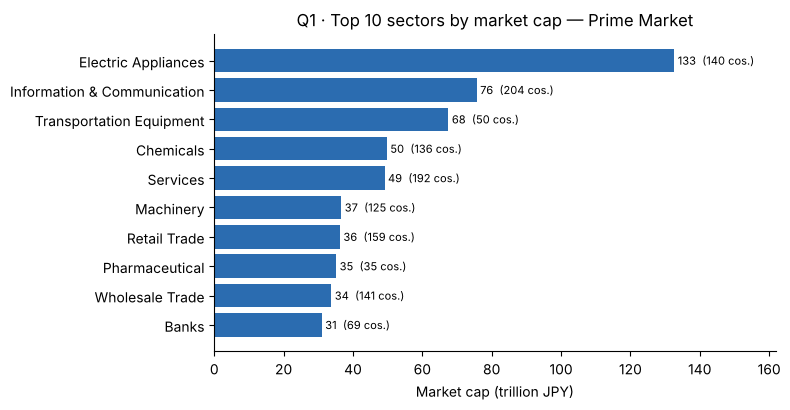

In [15]:
top5 = q1.head(5)
tot_prime = prime.market_cap.astype('float').sum()/1e12
print(f'Capitalización total del Prime Market: {tot_prime:,.0f} billones de JPY ({len(prime)} empresas)')
print(f"Top 5 sectores = {top5.pct_of_prime.sum():.1f}% del total")
fig, ax = plt.subplots(figsize=(8,4.2))
d = q1.sort_values('market_cap_trillion_jpy')
ax.barh(d.sector, d.market_cap_trillion_jpy, color='#2b6cb0')
for y,(v,n) in enumerate(zip(d.market_cap_trillion_jpy, d.companies)):
    ax.text(v+1, y, f'{v:,.0f}  ({n} cos.)', va='center', fontsize=8)
ax.set_xlabel('Market cap (trillion JPY)'); ax.set_title('Q1 · Top 10 sectors by market cap — Prime Market')
ax.spines[['top','right']].set_visible(False); ax.set_xlim(0, d.market_cap_trillion_jpy.max()*1.22)
plt.tight_layout(); plt.savefig('docs/q1_top_sectors.png', dpi=150); plt.show()

### Pregunta 2 — ¿Cómo se compara el tamaño típico de una empresa entre Prime, Standard y Growth?
Filtro: acciones con segmento definido (se excluyen fondos y *Unassigned*) · Agregación: conteo, **mediana** y **promedio** de capitalización. Se usa mediana porque la distribución está muy sesgada.

In [16]:
# SQLite no tiene MEDIAN: se obtiene con pandas sobre el resultado del JOIN
base = pd.read_sql('''
SELECT m.segment_name, p.market_cap
FROM security s JOIN price_snapshot p USING (securities_code) JOIN market_segment m USING (segment_id)
WHERE s.instrument_type='Equity' AND m.segment_name NOT IN ('Unassigned','Not applicable (fund)')''', con)
base['segment'] = base.segment_name.str.extract(r'^(Prime|Standard|Growth)')
q2 = (base.groupby('segment')['market_cap']
          .agg(companies='count', median_bn=lambda s: s.median()/1e9, mean_bn=lambda s: s.mean()/1e9, max_bn=lambda s: s.max()/1e9)
          .round(1).loc[['Prime','Standard','Growth']])
q2['mean_to_median'] = (q2.mean_bn/q2.median_bn).round(1)
q2

,companies,median_bn,mean_bn,max_bn,mean_to_median
segment,,,,,
Prime,1838,61.4,395.2,34351.2,6.4
Standard,1466,6.3,15.8,1120.9,2.5
Growth,458,7.6,19.3,937.4,2.5


/tmp/ipykernel_429/1938633589.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data, tick_labels=['Prime','Standard','Growth'], vert=True, patch_artist=True,


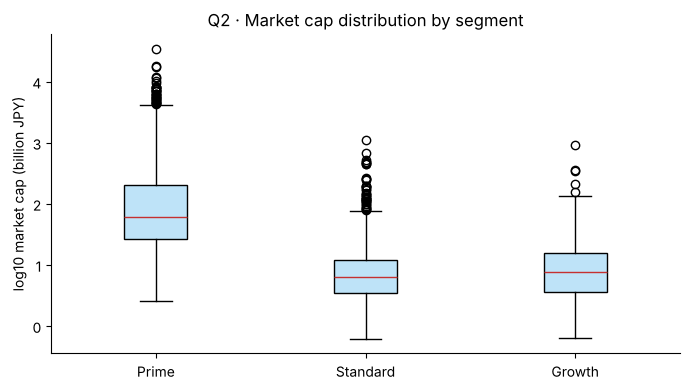

In [17]:
fig, ax = plt.subplots(figsize=(7,4))
data = [np.log10(base[base.segment==s].market_cap/1e9) for s in ['Prime','Standard','Growth']]
ax.boxplot(data, tick_labels=['Prime','Standard','Growth'], vert=True, patch_artist=True,
           boxprops=dict(facecolor='#bee3f8'), medianprops=dict(color='#c53030'))
ax.set_ylabel('log10 market cap (billion JPY)'); ax.set_title('Q2 · Market cap distribution by segment')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('docs/q2_segment_cap.png', dpi=150); plt.show()

## 5. Hallazgos
*(Ver las cifras exactas en las salidas de arriba; el texto final está en el README, sección "Data & cleaning".)*

In [18]:
r = q1.iloc[0]; pr = q2.loc['Prime']; st = q2.loc['Standard']; gr = q2.loc['Growth']
print(f"Q1: '{r.sector}' lidera el Prime Market con {r.market_cap_trillion_jpy} billones de JPY ({r.pct_of_prime}% del total); "
      f"los 5 primeros sectores suman {q1.head(5).pct_of_prime.sum():.1f}%.")
print(f"Q2: mediana Prime {pr.median_bn} mil millones JPY vs Standard {st.median_bn} vs Growth {gr.median_bn}; "
      f"el promedio de Prime ({pr.mean_bn}) es {pr.mean_to_median}x su mediana -> pocas empresas gigantes dominan.")
con.close()

Q1: 'Electric Appliances' lidera el Prime Market con 132.65 billones de JPY (18.3% del total); los 5 primeros sectores suman 51.7%.
Q2: mediana Prime 61.4 mil millones JPY vs Standard 6.3 vs Growth 7.6; el promedio de Prime (395.2) es 6.4x su mediana -> pocas empresas gigantes dominan.
